# Telugu Tokenizer Report For Phase-1

This notebook contains code and reports all the required statistics that are needed for submission in phase-1. I will also annotate parts and clarify the choices I have taken while implementing the project

Minimal AI help is taken to make this report

In [10]:
import json
from collections import Counter, defaultdict
from pathlib import Path


import sentencepiece as spm # used sentencepiece to train the Tokenizer
import matplotlib.pyplot as plt

## Corpus Examination

I sourced the corpus for Nepalese from several sources
- ekantipur.com
- gorkhapatra.com
- onlinekhabar.com
- ratopati.com
- Common Crawl
- Sangraha
- wikipedia

In [13]:
INPUT_FILE = "data.nosync/nepalese_combined_corpus_cleaned_v2.jsonl"

About 85% of the characters are from Sangraha and the rest 15% is from the other sources combined. This does not satisfy the 80:20 ratio given in project outline. No excuses, but the scraping from web and cleaning took alot more time than anticipated. And my calculations were off (characters/token) leading to 5% difference. 

Refer to `Nepalese/utils/token_count_by_source.json` for detailed stats

In [7]:
MODEL_FILE = "Tokenizer/models/nepalese_sentencepiece_bpe_6k/nepalese_bpe_6k.model"

In [8]:
sp = spm.SentencePieceProcessor(model_file=MODEL_FILE)

## Tokenizer Analysis

I trained a BPE model with vocabulary size of 6k. I have ensured that the 500M token mark is reached.

In [14]:
from utils.tokenizer_evaluation import TokenizerEvaluator

evaluator = TokenizerEvaluator(input_file=INPUT_FILE, model_file=MODEL_FILE)
evaluator.process_corpus()


PROCESSING CORPUS
Processed: 10,000 | Tokens: 7,779,456
Processed: 20,000 | Tokens: 18,723,425
Processed: 30,000 | Tokens: 31,698,369
Processed: 40,000 | Tokens: 41,710,509
Processed: 50,000 | Tokens: 48,245,348
Processed: 60,000 | Tokens: 56,069,950
Processed: 70,000 | Tokens: 63,382,564
Processed: 80,000 | Tokens: 71,929,023
Processed: 90,000 | Tokens: 79,517,914
Processed: 100,000 | Tokens: 84,486,463
Processed: 110,000 | Tokens: 89,492,762
Processed: 120,000 | Tokens: 94,377,804
Processed: 130,000 | Tokens: 99,393,133
Processed: 140,000 | Tokens: 104,425,311
Processed: 150,000 | Tokens: 109,297,649
Processed: 160,000 | Tokens: 114,329,508
Processed: 170,000 | Tokens: 119,241,520
Processed: 180,000 | Tokens: 124,222,608
Processed: 190,000 | Tokens: 129,030,160
Processed: 200,000 | Tokens: 133,954,276
Processed: 210,000 | Tokens: 138,912,599
Processed: 220,000 | Tokens: 143,837,104
Processed: 230,000 | Tokens: 148,744,306
Processed: 240,000 | Tokens: 153,648,577
Processed: 250,000 | 

#### Total Token Count

In [15]:
token_count = evaluator.get_total_token_count()
print(f"Total tokens in the corpus: {token_count}")

Total tokens in the corpus: {'documents': 977991, 'characters': 2008516229, 'tokens': 519817461}


#### Token percentage by source

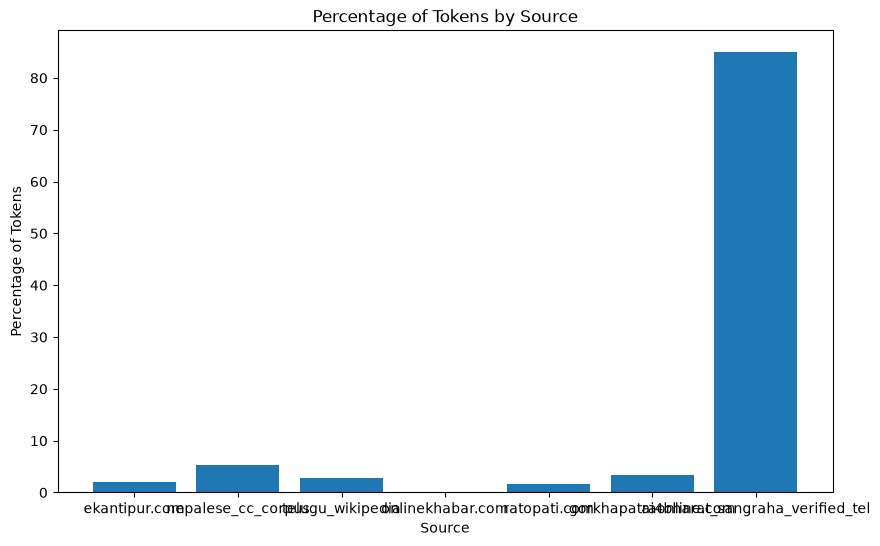

In [16]:
results = evaluator.get_token_percentage_by_source()

sources = list(results.keys())
percentages = {source: results[source]["token_percentage"] for source in sources}

plt.figure(figsize=(10, 6))
plt.bar(sources, percentages.values())
plt.xlabel("Source")
plt.ylabel("Percentage of Tokens")
plt.title("Percentage of Tokens by Source")
plt.show()

#### unk statistics

In [17]:
unk_results = evaluator.get_unk_statistics()

print("Unknown Token Statistics:")
print(f"Total unknown tokens: {unk_results['total_unk_tokens']}")
print(f"documents with unknown tokens (percentage): {unk_results['documents_with_unk_percentage']:.2f}%")
print(f"unk token percentage: {unk_results['unk_token_percentage']:.2f}%")

Unknown Token Statistics:
Total unknown tokens: 1197408
documents with unknown tokens (percentage): 16.74%
unk token percentage: 0.23%


#### Fertility

In [18]:
fertility_results = evaluator.get_fertility()
print("Fertility Statistics:")
print(f"Total number of words: {fertility_results['total_words']}")
print(f"Total number of tokens: {fertility_results['total_token_pieces']}")
print(f"Fertility (tokens per word): {fertility_results['fertility']:.2f}")

Fertility Statistics:
Total number of words: 310885940
Total number of tokens: 519817461
Fertility (tokens per word): 1.67


#### Vocabulary utilisation

In [19]:
vocabulary_results = evaluator.get_vocabulary_utilisation()

print("Vocabulary Utilisation Statistics:")
print(f"Total vocabulary size: {vocabulary_results['vocabulary_size']}")
print(f"Number of unique tokens used in the corpus: {vocabulary_results['used_tokens']}")
print(f"Percentage of vocabulary used: {vocabulary_results['vocabulary_utilisation_percentage']:.2f}%")

Vocabulary Utilisation Statistics:
Total vocabulary size: 6000
Number of unique tokens used in the corpus: 5997
Percentage of vocabulary used: 99.95%


#### Token distribution

/opt/anaconda3/envs/lma/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 2404 (\N{DEVANAGARI DANDA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/anaconda3/envs/lma/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 2325 (\N{DEVANAGARI LETTER KA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/anaconda3/envs/lma/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 2352 (\N{DEVANAGARI LETTER RA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/anaconda3/envs/lma/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 2331 (\N{DEVANAGARI LETTER CHA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/anaconda3/envs/lma/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 2350 (\N{DEVANAGARI LETTER MA}) missing from font(s

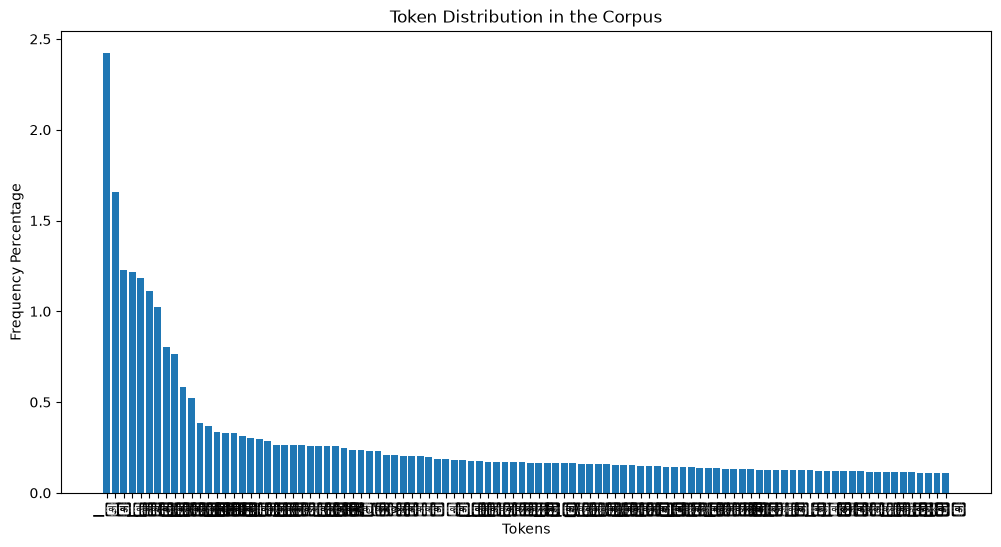

In [20]:
top_k = 100
token_distribution = evaluator.get_token_distribution(top_k=top_k)
Tokens = list(token_distribution[k]['token'] for k in range(top_k))
Frequency_percentage = list(token_distribution[k]['percentage'] for k in range(top_k))

plt.figure(figsize=(12, 6))
plt.bar(Tokens, Frequency_percentage)
plt.xlabel("Tokens")
plt.ylabel("Frequency Percentage")
plt.title("Token Distribution in the Corpus")
plt.show()

#### Rare Tokens

In [21]:
rare_tokens = evaluator.get_rare_tokens(max_frequency=160)['rare_tokens']

for i in range(len(rare_tokens)):
    token_info = rare_tokens[i]
    print(f"Token: {token_info['token']}, Frequency: {token_info['frequency']}")


Token: ▁विधे, Frequency: 110
Token: याधीश, Frequency: 115
Token: गरानी, Frequency: 134


#### Token Lengths

In [22]:
token_length_stats = evaluator.get_average_token_length()

print("Token length statistics:")
print(f"Average token length: {token_length_stats['average_token_length']:.2f}")
print(f"Minimum token length: {token_length_stats['minimum_token_length']}")
print(f"Maximum token length: {token_length_stats['maximum_token_length']}")

Token length statistics:
Average token length: 4.30
Minimum token length: 0
Maximum token length: 15
